# Рекомендации музыкальных треков
В этом проекте я попробовал подобрать пользователям музыку по истории прослушиваний. В данных есть миллион треков и 222 629 898 взаимодействий 1 373 221 пользователя. Названия треков, исполнителей, альбомов и жанров находятся в отдельном справочнике.

Сначала я проверил данные и посмотрел, как распределены прослушивания. Затем сравнил три подхода: популярные треки, персональные рекомендации ALS и ранжирование кандидатов с CatBoost. Для оценки оставил более поздние прослушивания, которые модели не видели при обучении.

Результаты получены за несколько запусков: анализ данных сохранился от полного расчёта, а CatBoost, итоговую выдачу и метрики я обновил отдельно. Для сдачи нужен готовый выполненный ноутбук; повторять расчёт в Jupyter Hub не требуется. По умолчанию стоит `review`: сохранённые результаты можно читать без выполнения. Run All в этом режиме остановится в первой кодовой ячейке до вычислений. Условия повторного расчёта описаны в README.


In [1]:
# review: только просмотр; resume: новый CatBoost и итоговая выдача; full: весь проект.
RUN_MODE = 'review'
ALLOW_ALS_TRAINING = False
ALLOW_CATBOOST_TRAINING = False
ALLOW_LEGACY_REUSE = False
PUBLISH_S3 = False
RUN_PIPELINE = RUN_MODE != 'review'
if RUN_MODE not in {'review','resume','full'}:
    raise ValueError('RUN_MODE: review, resume или full')
if not RUN_PIPELINE:
    raise RuntimeError('Режим просмотра: для чтения сохранённых результатов выполнение не требуется. Для контролируемого продолжения выберите resume и отдельно разрешите CatBoost и повторное использование старых артефактов. ALS и запись в S3 по умолчанию запрещены.')

import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '6'
from pathlib import Path
import configparser, gc, hashlib, json, time, urllib.request, uuid, shutil
from importlib.metadata import version
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb, boto3, faiss
from botocore.exceptions import ClientError
from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares
from catboost import CatBoostRanker, Pool
from catboost.utils import eval_metric
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED, K, CANDIDATES = 42, 10, 50
INNER_END, TRAIN_END = '2022-12-09', '2022-12-16'
CACHE_SCHEMA = 3
ALS_PARAMS = dict(factors=32, regularization=.1, iterations=12, num_threads=6, random_state=SEED)
WEIGHT_RECIPE = dict(name='1 + scale * log1p(plays)', scale=20, version=1)
HNSW_PARAMS = dict(M=24, efConstruction=80, efSearch=160, build_threads=1, search_threads=6)
CANDIDATE_PARAMS = dict(count=CANDIDATES, search_count=400, batch_size=256, filter_seen=True,
                        fallback='popular', score='inner_product', cold_start='popular', version=1)
SELECTION_PARAMS = dict(method='sorted_user_id_then_choice_without_replacement', seed=SEED,
                        max_users=20000, validation_fraction=.2, exclude_noninformative=True)
FEATURE_RECIPE = dict(als_score='factor_dot_product', log_popularity='log1p(train_events)',
                      log_activity='log1p(unique_train_tracks)', sources='als_branch_with_fallback,popular', version=1)
RANKER_PARAMS = dict(iterations=200, depth=6, learning_rate=.08, loss_function='YetiRank',
                     eval_metric=f'NDCG:top={K}', random_seed=SEED, thread_count=6,
                     allow_writing_files=False, verbose=False)
EARLY_STOPPING_ROUNDS = 25
LIBRARY_VERSIONS = {name: version(name) for name in ('numpy','pandas','scipy','implicit','catboost','faiss-cpu')}
WORK = Path(os.environ.get('RECSYS_WORKDIR', str(Path.home()/'recsys-data')))
RAW, OUT = WORK/'raw', WORK/'output-v3'
CACHE = WORK/'cache-v3'  # Старые кэши и модели в WORK не изменяются.
for p in (RAW, OUT, CACHE, WORK/'spill'): p.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
con.execute("SET memory_limit='3GB'")
con.execute('SET threads=4')
con.execute("SET max_temp_directory_size='6GB'")
con.execute(f"SET temp_directory='{WORK/'spill'}'")
con.execute('SET preserve_insertion_order=false')
faiss.omp_set_num_threads(HNSW_PARAMS['search_threads'])
BUCKET = 'hda-s3-20261107-6104ff762354'
s3 = None

def get_s3():
    global s3
    if s3 is None:
        cfg=configparser.ConfigParser()
        cfg.read(Path.home()/'.config/mle-recsys/s3.ini')
        settings=cfg['s3']
        assert settings['bucket']==BUCKET
        s3=boto3.Session(region_name=settings['region']).client('s3',endpoint_url=settings['endpoint_url'])
        s3.head_bucket(Bucket=BUCKET)
    return s3

print('Python:', __import__('sys').version.split()[0], '| CPU:', os.cpu_count())

def query(sql): return con.execute(sql).fetchdf()
def upload_checked(path, key):
    # Отдельная повторная загрузка и SHA-256 проверяют весь файл, а не только заголовок.
    if not PUBLISH_S3 or (RUN_MODE=='resume' and key!='recsys/recommendations/recommendations.parquet'):
        print('S3 без изменений:',key)
        return
    client=get_s3()
    digest = file_hash(path)
    client.upload_file(str(path), BUCKET, key)
    check = WORK/('verify-'+uuid.uuid4().hex+'.parquet')
    try:
        client.download_file(BUCKET, key, str(check))
        assert file_hash(check) == digest
        a, b = pq.ParquetFile(path), pq.ParquetFile(check)
        assert a.metadata.num_rows == b.metadata.num_rows and a.schema_arrow.equals(b.schema_arrow)
        print(f's3://{BUCKET}/{key}: {b.metadata.num_rows:,} строк; повторное чтение и SHA-256 — OK')
    finally:
        check.unlink(missing_ok=True)

def write_json_atomic(path, value):
    temporary = path.with_name(path.name+'.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, sort_keys=True), encoding='utf-8')
    temporary.replace(path)


def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


DIGEST_INDEX = CACHE/'file-digests.json'
try:
    _digests = json.loads(DIGEST_INDEX.read_text(encoding='utf-8'))
except (OSError, ValueError):
    _digests = {}
if not isinstance(_digests,dict): _digests = {}


def file_hash(path, force=False):
    # Большие файлы повторно читаются только при изменении размера, mtime или ctime.
    # Для отдельной полной проверки можно вызвать file_hash(path, force=True).
    path = Path(path)
    stat = path.stat()
    stamp = dict(size=stat.st_size, mtime_ns=stat.st_mtime_ns, ctime_ns=stat.st_ctime_ns)
    key = str(path.resolve())
    saved = _digests.get(key, {})
    if not force and saved.get('stamp') == stamp and isinstance(saved.get('sha256'),str):
        return saved['sha256']
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for part in iter(lambda:stream.read(8*1024*1024), b''): h.update(part)
    digest = h.hexdigest()
    _digests[key] = dict(stamp=stamp, sha256=digest)
    write_json_atomic(DIGEST_INDEX, _digests)
    return digest


def cache_metadata(path):
    return path.with_suffix(path.suffix+'.json')


def cache_valid(path, signature):
    if not path.exists() or not cache_metadata(path).exists(): return False
    try:
        info = json.loads(cache_metadata(path).read_text(encoding='utf-8'))
        return (info['schema'] == CACHE_SCHEMA and info['signature'] == signature
                and info['sha256'] == file_hash(path))
    except (OSError, ValueError, KeyError, TypeError):
        return False


def prepare_new_cache(path, training=None):
    if path.exists() or cache_metadata(path).exists():
        raise RuntimeError(f'Несовместимый или неполный кэш: {path}. Он сохранён. Для нового расчёта выберите другой CACHE-каталог.')
    if not RUN_PIPELINE:
        raise RuntimeError('Новый расчёт не разрешён: RUN_PIPELINE=False')
    if training not in {None,'als','catboost'}: raise ValueError('Неизвестный тип обучения')
    allowed = {'als':ALLOW_ALS_TRAINING,'catboost':ALLOW_CATBOOST_TRAINING}
    if training is not None and not allowed[training]:
        raise RuntimeError(f'Нет совместимой модели {path.name}; обучение {training} отдельно запрещено. Существующие модели сохранены.')


def record_cache(path, signature, training_info=None):
    info = dict(schema=CACHE_SCHEMA, signature=signature, sha256=file_hash(path))
    if training_info is not None: info['training'] = training_info
    write_json_atomic(cache_metadata(path), info)


def array_hash(values):
    values = np.ascontiguousarray(values)
    h = hashlib.sha256()
    h.update(str(values.dtype).encode()); h.update(str(values.shape).encode()); h.update(memoryview(values))
    return h.hexdigest()


def frame_hash(frame, columns):
    # Ограниченная выборка CatBoost, а не весь журнал взаимодействий.
    values = pd.util.hash_pandas_object(frame[columns], index=False).to_numpy(dtype=np.uint64)
    return fingerprint(dict(columns=columns, dtypes=[str(frame[c].dtype) for c in columns], rows=len(frame), values=array_hash(values)))


def require_zero(sql, message):
    assert int(con.execute(sql).fetchone()[0]) == 0, message


def validate_recommendations(view):
    require_zero(f'SELECT count(*) FROM (SELECT user_id,track_id FROM {view} GROUP BY ALL HAVING count(*)>1)', 'Повтор пары пользователь–трек')
    require_zero(f"SELECT count(*) FROM {view} r JOIN events e USING(user_id,track_id) WHERE e.started_at<DATE '{TRAIN_END}'", 'В выдаче есть обучающая история')
    require_zero(f'SELECT count(*) FROM {view} WHERE user_id IS NULL OR track_id IS NULL OR score IS NULL OR NOT isfinite(score) OR rank IS NULL', 'Недопустимые оценки или ранги')
    require_zero(f'SELECT count(*) FROM (SELECT user_id FROM {view} GROUP BY user_id HAVING count(*)<>{K} OR count(DISTINCT rank)<>{K} OR min(rank)<>1 OR max(rank)<>{K})', 'Должно быть K разных последовательных рангов на пользователя')
    require_zero(f'SELECT count(*) FROM {view} r ANTI JOIN user_map u USING(user_id)', 'Неизвестный пользователь')
    require_zero(f'SELECT count(*) FROM {view} r ANTI JOIN item_map i USING(track_id)', 'Неизвестный трек')
    assert con.execute(f'SELECT count(DISTINCT user_id) FROM {view}').fetchone()[0] == len(users)


def validate_similar(path):
    table = f"read_parquet('{path}')"
    require_zero(f'SELECT count(*) FROM {table} WHERE track_id IS NULL OR similar_track_id IS NULL OR track_id=similar_track_id OR score IS NULL OR NOT isfinite(score) OR score < -1.00001 OR score>1.00001 OR rank IS NULL OR rank<1 OR rank>{K}', 'Недопустимые соседи, ранги или оценки')
    require_zero(f'SELECT count(*) FROM (SELECT track_id,similar_track_id FROM {table} GROUP BY ALL HAVING count(*)>1)', 'Повторяющиеся пары соседей')
    require_zero(f'SELECT count(*) FROM (SELECT track_id,rank FROM {table} GROUP BY ALL HAVING count(*)>1)', 'Повторяющиеся ранги соседей')
    require_zero(f'SELECT count(*) FROM (SELECT track_id FROM {table} GROUP BY track_id HAVING count(*)>{K} OR min(rank)<>1 OR max(rank)<>count(*))', 'Непоследовательные ранги соседей')


# Результат проверки старых файлов на чтение. Это не сведения нового обучения.
LEGACY_EVIDENCE = json.loads('{"artifacts": {"catalog": {"path": "raw/catalog_names.parquet", "sha256": "d3898b667d1982314a910a7cabc638e0c49de771a486704343c1904fbe1841ea", "size": 36146495}, "events": {"columns": ["user_id", "track_id", "track_seq", "started_at"], "path": "output/events.parquet", "rows": 222629898, "sha256": "967e374c2750ac3483dc7f4301d9d01c0cf4c8b42335d60aa3a6ffc648de33c9", "size": 959492260}, "inner_als": {"boundary": "2022-12-09", "compatibility": "probable_documented_pipeline", "legacy_signature": {"boundary": "2022-12-09", "factors": 32, "items": 1000000, "iterations": 12, "regularization": 0.1, "seed": 42, "source": {"interactions": "5edc7f5f0624a7651691894ea44375fcd6ea2689bda8f9aed1edaf28f8a68796", "tracks": "6e6050eeea39cb23344cf6341b513060c873acfa4fa6ea9e16bdfcca121a611e"}, "users": 1373221}, "limitations": ["Original weighted CSR fingerprint and original-fit run record were not saved."], "parameters": {"alpha": 1, "calculate_training_loss": false, "cg_steps": 3, "dtype": "float32", "factors": 32, "iterations": 12, "num_threads": 6, "random_state": 42, "regularization": 0.1, "use_cg": true, "use_native": true}, "path": "inner-als.npz", "sha256": "80637d5ca2ee3444ff22976ea51cbf90018cae9bd083ecbf608780a65a742dc9", "size": 303775683}, "inner_index": {"active_sha256": "6ddd05529d2b4a32af9631d664bfc7af5990eaa535b29c060564d77d70142937", "cosine": false, "factors_sha256": "a02b6a084d7d9130d4351b2c6ad116af082adea0046e844c863772671f818754", "hnsw": {"M": 24, "build_threads": 1, "efConstruction": 80, "efSearch": 160, "search_threads": 6}, "max_vector_error": 0, "path": "index-581b45ce71ab1a2a.faiss", "sha256": "d1a489d06958b4a66777bad18ca6eb70757e385ba29a358dc5c98b0dac72cc7b", "size": 335847162, "vectors_checked": 999049}, "inner_pairs": {"boundary": "2022-12-09", "path": "inner-pairs.parquet", "rows": 200834917, "sample_pairs": 258, "sample_source_match": true, "sha256": "19642aec820722b3ac7e51aefa5e0f79947ee5c6c5d3efe32d0a2151c8b2a0c9", "size": 557182617}, "items": {"columns": ["track_id", "albums", "artists", "genres", "title", "artist_names", "album_names", "genre_names"], "path": "output/items.parquet", "rows": 1000000, "sha256": "8000af734851f1757d7b021ae3e816240031ef3cd1134838da88e72a7f366dcd", "size": 41209947}, "personal_als": {"columns": ["user_id", "track_id", "score", "rank"], "compatibility": "probable_documented_pipeline", "history_check": "sample_users_only", "path": "output/personal_als.parquet", "rows": 13732210, "sha256": "57cbbf281a4ef475de1b0166c0510db029e90a6bcb0c194ec0107d63479873d9", "size": 104696040, "structure_checked": true}, "raw_interactions": {"path": "raw/interactions.parquet", "sha256": "5edc7f5f0624a7651691894ea44375fcd6ea2689bda8f9aed1edaf28f8a68796", "size": 1208078471}, "raw_tracks": {"path": "raw/tracks.parquet", "sha256": "6e6050eeea39cb23344cf6341b513060c873acfa4fa6ea9e16bdfcca121a611e", "size": 18938128}, "recommendations": {"columns": ["user_id", "track_id", "score", "rank"], "compatibility": "probable_documented_pipeline", "history_check": "sample_users_only", "path": "output/recommendations.parquet", "rows": 13732210, "sha256": "184f5e823549e7bf8604af8f8225465269ef2c0b3b41f73668e87c53a6df8d79", "size": 81388212, "structure_checked": true}, "similar": {"columns": ["track_id", "similar_track_id", "score", "rank"], "compatibility": "probable_documented_pipeline", "path": "output/similar.parquet", "rows": 9996950, "sha256": "20bb15e4a252206bad22ec923717b9a8d18d9c4a9580fde353c934e66cca43c1", "size": 98000115, "structure_checked": true}, "top_popular": {"columns": ["user_id", "track_id", "score", "rank"], "compatibility": "probable_documented_pipeline", "history_check": "sample_users_only", "path": "output/top_popular.parquet", "rows": 13732210, "sha256": "fc2b7ae912c4aa65c6173ad897239a612e726929cf8663f97a8b64de2ab7aa19", "size": 8757355, "structure_checked": true}, "train_als": {"boundary": "2022-12-16", "compatibility": "probable_documented_pipeline", "legacy_signature": {"boundary": "2022-12-16", "factors": 32, "items": 1000000, "iterations": 12, "regularization": 0.1, "seed": 42, "source": {"interactions": "5edc7f5f0624a7651691894ea44375fcd6ea2689bda8f9aed1edaf28f8a68796", "tracks": "6e6050eeea39cb23344cf6341b513060c873acfa4fa6ea9e16bdfcca121a611e"}, "users": 1373221}, "limitations": ["Original weighted CSR fingerprint and original-fit run record were not saved."], "parameters": {"alpha": 1, "calculate_training_loss": false, "cg_steps": 3, "dtype": "float32", "factors": 32, "iterations": 12, "num_threads": 6, "random_state": 42, "regularization": 0.1, "use_cg": true, "use_native": true}, "path": "train-als.npz", "sha256": "704e7524b5d9a77f55c0c92bfc9021c83b7ae16de519c23e3085d9254788249d", "size": 303775683}, "train_cosine_index": {"active_sha256": "facd871b5d6e97d363bf2b9ca86dcf62bef80e016e8837d904f483510c6ab2d8", "cosine": true, "factors_sha256": "b7d3514db4cb5ae435719c741509aac5a4eec137fdcda3a9973d27d368365be6", "hnsw": {"M": 24, "build_threads": 1, "efConstruction": 80, "efSearch": 160, "search_threads": 6}, "max_vector_error": 0, "path": "index-19b8a876235e1c7e.faiss", "sha256": "a3e4bc9d41b5f80a3bc92b2595df3bef8af5bfbdb56b492ed79c2898d4abba57", "size": 336063842, "vectors_checked": 999695}, "train_index": {"active_sha256": "facd871b5d6e97d363bf2b9ca86dcf62bef80e016e8837d904f483510c6ab2d8", "cosine": false, "factors_sha256": "b7d3514db4cb5ae435719c741509aac5a4eec137fdcda3a9973d27d368365be6", "hnsw": {"M": 24, "build_threads": 1, "efConstruction": 80, "efSearch": 160, "search_threads": 6}, "max_vector_error": 0, "path": "index-ac619ff1f865d3d5.faiss", "sha256": "96176a4781dc6ebc38a9904ef69c8f7246169e63d1b0247b29b4a554eb53de11", "size": 336063842, "vectors_checked": 999695}, "train_pairs": {"boundary": "2022-12-16", "path": "train-pairs.parquet", "rows": 208731252, "sample_pairs": 299, "sample_source_match": true, "sha256": "2722095335711d8227a5425fdd2e4e4c8b2eb55586b7174de258490fb9a73a5e", "size": 579477535}}, "checked_at_utc": "2026-11-21T09:41:49.493286+00:00", "libraries": {"catboost": "1.2.2", "faiss-cpu": "1.8.0.post1", "implicit": "0.7.2", "numpy": "1.26.4", "pandas": "2.1.1", "scipy": "1.11.4"}, "maps": {"items": "e76f0f6a127077f78ec4944f99ecae3dbaa19cdcf25af7abea933b93ade6595b", "users": "36b9fee5ac3b322a7419d3c6a438a0eccd2c77918664ad5ea0f4bf8ad58c1bcb"}, "prepared_events_sample_match": true, "sample_users": [0, 1, 687268, 1374582], "shape": [1373221, 1000000]}')
LEGACY_CONFIG = dict(
    als=dict(factors=32,regularization=.1,iterations=12,num_threads=6,random_state=42),
    weights=dict(name='1 + scale * log1p(plays)',scale=20,version=1),
    hnsw=dict(M=24,efConstruction=80,efSearch=160,build_threads=1,search_threads=6),
    candidates=dict(count=50,search_count=400,batch_size=256,filter_seen=True,
                    fallback='popular',score='inner_product',cold_start='popular',version=1))
_legacy_refs={}

def assert_legacy_contract():
    if not ALLOW_LEGACY_REUSE:
        raise RuntimeError('Повторное использование старой ALS требует ALLOW_LEGACY_REUSE=True. Файлы, данные и индексы проверены, но первичный отпечаток взвешенной CSR не сохранился; происхождение обучения вероятно совместимо, а не доказано новым fit.')
    if INNER_END!='2022-12-09' or TRAIN_END!='2022-12-16' or K!=10:
        raise RuntimeError('Периоды или K отличаются от проверенных старых артефактов')
    for actual,expected in [(ALS_PARAMS,LEGACY_CONFIG['als']),(WEIGHT_RECIPE,LEGACY_CONFIG['weights']),
                            (HNSW_PARAMS,LEGACY_CONFIG['hnsw']),(CANDIDATE_PARAMS,LEGACY_CONFIG['candidates']),
                            (LIBRARY_VERSIONS,LEGACY_EVIDENCE['libraries'])]:
        if actual!=expected: raise RuntimeError('Параметры или библиотеки отличаются от проверенной схемы. Автоматический перенос запрещён.')

def legacy_file(role):
    info=LEGACY_EVIDENCE['artifacts'][role]
    path=WORK/info['path']
    if not path.is_file(): raise FileNotFoundError(f'Нет проверенного артефакта {role}: {path}')
    if path.stat().st_size!=info['size'] or file_hash(path)!=info['sha256']:
        raise RuntimeError(f'Артефакт {role} изменился: {path}. Использование остановлено.')
    return path

def reuse_legacy(role,signature):
    assert_legacy_contract()
    if role in {'ranker','recommendations'}: raise RuntimeError('Старый CatBoost и его итоговая выдача не переносятся как новые')
    if 'SOURCE_HASHES' in globals():
        expected={name:LEGACY_EVIDENCE['artifacts']['raw_'+name]['sha256'] for name in ('tracks','interactions')}
        if SOURCE_HASHES!=expected: raise RuntimeError('Источники отличаются от проверенных')
    if 'MAP_HASHES' in globals() and MAP_HASHES!=LEGACY_EVIDENCE['maps']:
        raise RuntimeError('Изменилось отображение ID')
    info=LEGACY_EVIDENCE['artifacts'][role]
    if role in {'inner_als','train_als','inner_pairs','train_pairs'}:
        actual_boundary=signature.get('boundary',signature.get('data',{}).get('boundary'))
        if actual_boundary!=info['boundary']: raise RuntimeError('Период артефакта не соответствует запросу')
    key=(role,fingerprint(signature))
    if key not in _legacy_refs:
        path=legacy_file(role)
        origin=dict(origin='reused_legacy_artifact',role=role,source_path=LEGACY_EVIDENCE['artifacts'][role]['path'],path_base='RECSYS_WORKDIR',
                    signature=signature,sha256=LEGACY_EVIDENCE['artifacts'][role]['sha256'],
                    verification=LEGACY_EVIDENCE['checked_at_utc'],
                    training_provenance='Original weighted CSR fingerprint and original-fit run record were not saved.',
                    compatibility='probable_documented_pipeline' if role.endswith('_als') or role in {'top_popular','personal_als','similar'} else 'verified_file_and_dependencies')
        refs=CACHE/'legacy-refs'; refs.mkdir(parents=True,exist_ok=True)
        ref=refs/f'{role}-{key[1][:20]}.json'
        if ref.exists():
            if json.loads(ref.read_text(encoding='utf-8'))!=origin: raise RuntimeError('Запись ссылки не соответствует проверке')
        else: write_json_atomic(ref,origin)
        _legacy_refs[key]=path
    return _legacy_refs[key]

def preflight_resume():
    # Только проверки наличия и договорённости о происхождении, до больших запросов.
    if ALLOW_ALS_TRAINING: raise RuntimeError('В режиме resume обучение ALS должно оставаться запрещённым')
    assert_legacy_contract()
    roles=['raw_tracks','raw_interactions','items','events','inner_pairs','train_pairs',
           'inner_als','train_als','inner_index','train_index','train_cosine_index',
           'top_popular','personal_als','similar']
    missing=[str(WORK/LEGACY_EVIDENCE['artifacts'][r]['path']) for r in roles
             if not (WORK/LEGACY_EVIDENCE['artifacts'][r]['path']).is_file()]
    if missing: raise FileNotFoundError('Не хватает артефактов продолжения: '+', '.join(missing))
    if shutil.disk_usage(WORK).free < 8*1024**3: raise RuntimeError('Для продолжения нужен запас не менее 8 GiB диска; файлы автоматически не удаляются')
    for role in ('inner_als','train_als'): legacy_file(role)
    print('Продолжение: старые ALS не обучаются; подтверждены файлы и схема. Ограничение происхождения первого fit явно принято.')

def block_signature(signature,start,end):
    return dict(config=signature,start=int(start),end=int(end))

def block_structure_ok(path,signature,start,end):
    try:
        f=pq.ParquetFile(path)
        if (f.schema_arrow.metadata or {}).get(b'recsys_signature')!=fingerprint(signature).encode(): return False
        expected=pa.schema([('user_id',pa.int64()),('track_id',pa.int64()),('score',pa.float32()),('rank',pa.int16())])
        if not f.schema_arrow.remove_metadata().equals(expected) or f.metadata.num_rows!=(end-start)*K: return False
        frame=f.read().to_pandas()  # Не более 25 600 * K строк одного блока.
        if not np.array_equal(np.sort(frame.user_id.unique()),users[start:end]): return False
        if frame.isna().any().any() or not np.isfinite(frame.score.to_numpy()).all(): return False
        if frame.duplicated(['user_id','track_id']).any() or frame.duplicated(['user_id','rank']).any(): return False
        positions=np.searchsorted(items,frame.track_id.to_numpy())
        if np.any(positions>=len(items)) or not np.array_equal(items[positions],frame.track_id.to_numpy()): return False
        row_positions=np.searchsorted(users,frame.user_id.to_numpy())
        if np.any(np.asarray(matrix[row_positions,positions]).ravel()!=0): return False
        groups=frame.groupby('user_id')['rank'].agg(['size','min','max'])
        return bool(((groups['size']==K)&(groups['min']==1)&(groups['max']==K)).all())
    except Exception:
        return False  # Повреждённый блок не считается готовым; оригинал не изменяется.

def ready_block(folder,signature,start,end):
    prefix=f'{start:08d}-{fingerprint(signature)[:16]}-'
    for path in sorted(folder.glob(prefix+'*.parquet')):
        if not block_structure_ok(path,signature,start,end): continue
        if cache_valid(path,signature): return path
        # Если Parquet-файл уже сохранился, а дополнительный JSON-файл с информацией о результате ещё не записался.
        if not cache_metadata(path).exists():
            record_cache(path,signature)
            return path
    return None

def pending_block(folder,signature,start):
    complete=folder/f'{start:08d}-{fingerprint(signature)[:16]}-{uuid.uuid4().hex[:12]}.parquet'
    return complete.with_suffix('.partial'),complete

def result_ready(path,signature):
    if not path.exists(): return False
    try:
        f=pq.ParquetFile(path)
        expected=pa.schema([('user_id',pa.int64()),('track_id',pa.int64()),('score',pa.float32()),('rank',pa.int16())])
        if not f.schema_arrow.remove_metadata().equals(expected) or f.metadata.num_rows!=len(users)*K: return False
        if (f.schema_arrow.metadata or {}).get(b'recsys_signature')!=fingerprint(signature).encode(): return False
        if cache_valid(path,signature): return True
        if cache_metadata(path).exists(): return False
        # Полный файл уже переименован, но sidecar не успел сохраниться при остановке.
        con.execute(f"CREATE OR REPLACE VIEW _result_recovery AS SELECT * FROM read_parquet('{path}')")
        validate_recommendations('_result_recovery')
        record_cache(path,signature)
        return True
    except Exception:
        return False


if RUN_MODE=='resume': preflight_resume()


/home/ubuntu/venvs/mle-recsys/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.10.12 | CPU: 6


Продолжение: старые ALS не обучаются; подтверждены файлы и схема. Ограничение происхождения первого fit явно принято.


# Этап 1. Знакомство с данными
Для начала я загрузил tracks.parquet, catalog_names.parquet и interactions.parquet. Мне нужно было понять, какие поля есть в каждом файле и можно ли связать прослушивания с треками и названиями.

Файл взаимодействий слишком большой для обычной таблицы pandas, поэтому я проверял его запросами DuckDB. Ниже показаны схемы, размеры таблиц, пропуски, повторы и ссылки на неизвестные треки.


In [2]:
if RUN_MODE=='resume':
    items_path=legacy_file('items')
    events_path=legacy_file('events')
    SOURCE_HASHES={name:file_hash(legacy_file('raw_'+name)) for name in ('tracks','interactions')}
    print('Готовые данные проверены и открываются локально; подготовка и скачивание не повторяются.')
else:
    for name in ('tracks','catalog_names','interactions'):
        path = RAW/(name+'.parquet')
        if not path.exists():
            partial = path.with_suffix('.part')
            urllib.request.urlretrieve('https://storage.yandexcloud.net/mle-data/ym/'+path.name, partial)
            partial.rename(path)
        f = pq.ParquetFile(path)
        print(name, f'{f.metadata.num_rows:,} строк', f'{path.stat().st_size/1e6:.1f} МБ')
        display(pd.DataFrame({'столбец':f.schema_arrow.names,'тип':[str(x.type) for x in f.schema_arrow]}))
    SOURCE_HASHES={name:file_hash(RAW/(name+'.parquet')) for name in ('tracks','interactions')}
    con.execute(f"CREATE VIEW tracks AS SELECT * FROM read_parquet('{RAW/'tracks.parquet'}')")
    con.execute(f"CREATE VIEW catalog AS SELECT * FROM read_parquet('{RAW/'catalog_names.parquet'}')")
    con.execute(f"CREATE VIEW raw_events AS SELECT user_id,track_id,track_seq,started_at FROM read_parquet('{RAW/'interactions.parquet'}')")
    display(query('SELECT * FROM raw_events LIMIT 5'))
    display(query('SELECT type,count(*) AS records FROM catalog GROUP BY type'))


tracks 1,000,000 строк 18.9 МБ


,столбец,тип
0,track_id,int64
1,albums,list<element: int64>
2,artists,list<element: int64>
3,genres,list<element: int64>


catalog_names 1,812,471 строк 36.1 МБ


,столбец,тип
0,id,int64
1,type,string
2,name,string


interactions 222,629,898 строк 1208.1 МБ


,столбец,тип
0,user_id,int32
1,track_id,int32
2,track_seq,int16
3,started_at,timestamp[ns]
4,__index_level_0__,int64


,user_id,track_id,track_seq,started_at
0,0,99262,1,2022-07-17
1,0,589498,2,2022-07-19
2,0,590262,3,2022-07-21
3,0,590303,4,2022-07-22
4,0,590692,5,2022-07-22


,type,records
0,album,658724
1,genre,166
2,track,1000000
3,artist,153581


In [3]:
if RUN_MODE=='full':
    checks = {}
    checks['tracks'] = query('SELECT count(*) AS rows, count(*)-count(DISTINCT track_id) AS duplicate_ids, count(*) FILTER(WHERE track_id IS NULL) AS null_ids FROM tracks')
    checks['catalog'] = query('SELECT count(*) AS rows,count(*) FILTER(WHERE id IS NULL OR type IS NULL OR name IS NULL) AS null_rows FROM catalog')
    checks['catalog_duplicate_keys'] = query('SELECT count(*) AS duplicate_keys FROM (SELECT type,id FROM catalog GROUP BY type,id HAVING count(*)>1)')
    checks['events'] = query('SELECT count(*) AS rows,count(*) FILTER(WHERE user_id IS NULL OR track_id IS NULL OR started_at IS NULL OR track_seq IS NULL) AS null_rows, min(started_at) AS first_date,max(started_at) AS last_date,count(DISTINCT user_id) AS users FROM raw_events')
    checks['unknown_tracks'] = query('SELECT count(*) AS events FROM raw_events e ANTI JOIN tracks t USING(track_id)')
    # Повторное прослушивание не равно ошибке. Точные дубликаты проверяем по всем смысловым полям.
    checks['exact_duplicate_events'] = query('SELECT coalesce(sum(n-1),0)::BIGINT AS extra_rows FROM (SELECT user_id,track_id,track_seq,started_at,count(*) AS n FROM raw_events GROUP BY ALL HAVING count(*)>1)')
    for name, table in checks.items():
        print(name); display(table)
    assert checks['tracks'].duplicate_ids.iloc[0] == 0
    assert checks['catalog_duplicate_keys'].duplicate_keys.iloc[0] == 0
    assert checks['events'].null_rows.iloc[0] == 0
    assert checks['unknown_tracks'].events.iloc[0] == 0

    relations=[]
    for field,kind in [('artists','artist'),('albums','album'),('genres','genre')]:
        row = query(f"SELECT count(*) AS links,count(*) FILTER(WHERE c.id IS NULL) AS unknown_links,count(DISTINCT t.track_id) FILTER(WHERE c.id IS NULL) AS tracks_with_unknown FROM tracks t, unnest(t.{field}) v(id) LEFT JOIN catalog c ON c.id=v.id AND c.type='{kind}'")
        row['empty_lists'] = query(f'SELECT count(*) AS n FROM tracks WHERE {field} IS NULL OR len({field})=0').n.iloc[0]
        row.insert(0,'relation',field); relations.append(row)
    display(pd.concat(relations,ignore_index=True))
else:
    print('Проверки исходных таблиц сохранены от прежнего расчёта; в resume проверяется целостность готовых файлов.')


tracks


,rows,duplicate_ids,null_ids
0,1000000,0,0


catalog


,rows,null_rows
0,1812471,0


catalog_duplicate_keys


,duplicate_keys
0,0


... (3 outputs left out)

,events
0,0


exact_duplicate_events


,extra_rows
0,0


,relation,links,unknown_links,tracks_with_unknown,empty_lists
0,artists,1264212,0,0,15369
1,albums,3128808,0,0,18
2,genres,1652658,48369,48345,3687


## Подготовка данных
Я сохранил идентификаторы и порядок прослушиваний `track_seq`, а к трекам добавил названия из справочника. Если название не удалось найти, использовал «Неизвестно». Пустой список жанров или исполнителей сам по себе не стал причиной удалять трек.

Повторные прослушивания могут отражать интерес пользователя, поэтому исходные события я не удалял. Точные дубликаты проверил отдельно. При построении матрицы ALS события одной пары пользователь–трек суммируются: так модель учитывает частоту прослушивания.


In [4]:
if RUN_MODE=='full':
    for field,kind in [('artists','artist'),('albums','album'),('genres','genre')]:
        con.execute(f"CREATE TEMP TABLE names_{field} AS SELECT t.track_id,list(coalesce(c.name,'Неизвестно') ORDER BY v.pos) AS {field}_names FROM tracks t, unnest(t.{field}) WITH ORDINALITY v(id,pos) LEFT JOIN catalog c ON c.id=v.id AND c.type='{kind}' GROUP BY t.track_id")
    items_path, events_path = OUT/'items.parquet', OUT/'events.parquet'
    con.execute(f"COPY (SELECT t.*,coalesce(c.name,'Неизвестно') AS title,coalesce(a.artists_names,[]::VARCHAR[]) AS artist_names,coalesce(b.albums_names,[]::VARCHAR[]) AS album_names,coalesce(g.genres_names,[]::VARCHAR[]) AS genre_names FROM tracks t LEFT JOIN catalog c ON c.id=t.track_id AND c.type='track' LEFT JOIN names_artists a USING(track_id) LEFT JOIN names_albums b USING(track_id) LEFT JOIN names_genres g USING(track_id)) TO '{items_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.execute(f"COPY (SELECT * FROM raw_events) TO '{events_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    for field in ('artists','albums','genres'): con.execute(f'DROP TABLE names_{field}')
    display(query(f"SELECT * FROM read_parquet('{items_path}') LIMIT 5"))
else:
    print('Повторная подготовка items/events пропущена.')


,track_id,albums,artists,genres,title,artist_names,album_names,genre_names
0,24745635,[2897424],"[680809, 1283946]","[21, 22]",Небо для тебя,"[Мурат Тхагалегов, Амирина]",[Я тебя забываю],"[folk, caucasian]"
1,24745636,[2897424],[680809],"[21, 22]",Малышка (Богиня),[Мурат Тхагалегов],[Я тебя забываю],"[folk, caucasian]"
2,24745637,[2897424],[680809],"[21, 22]",Чэф,[Мурат Тхагалегов],[Я тебя забываю],"[folk, caucasian]"
3,24745638,[2897424],[680809],"[21, 22]",Дианочка,[Мурат Тхагалегов],[Я тебя забываю],"[folk, caucasian]"
4,24745639,[2897424],[680809],"[21, 22]",Отомщу,[Мурат Тхагалегов],[Я тебя забываю],"[folk, caucasian]"


# Этап 2. Что пользователи слушают
Здесь я посмотрел распределение числа разных треков на пользователя, самые популярные треки и жанры, а также треки без прослушиваний. Это помогает понять, насколько активность пользователей и популярность музыки различаются.

Для этого анализа использовал весь набор данных. В признаки моделей эти общие подсчёты не попадают: популярность и активность для рекомендаций считаются отдельно, только по истории до соответствующей даты. Ниже оставлены таблицы, графики и выводы из первоначального анализа.


,events,tracks
count,1.373221e+06,1.373221e+06
mean,1.621224e+02,1.621224e+02
std,3.512846e+02,3.512846e+02
min,1.000000e+00,1.000000e+00
50%,5.500000e+01,5.500000e+01
90%,3.890000e+02,3.890000e+02
95%,6.500000e+02,6.500000e+02
99%,1.576000e+03,1.576000e+03
max,1.663700e+04,1.663700e+04


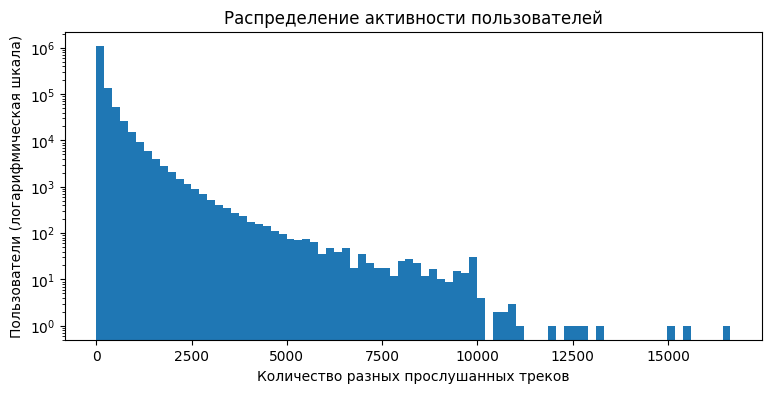

Медиана — **55** разных треков; 90% пользователей прослушали не больше **389**. Разброс активности учитываем отдельным признаком ранжирования.

,track_id,events,listeners,title,artist_names,album_names
0,53404,111062.0,111062,Smells Like Teen Spirit,[Nirvana],"[Nevermind, Nirvana, Nevermind, Nevermind, Nev..."
1,33311009,106921.0,106921,Believer,[Imagine Dragons],"[Shape Of Pop, NOW That's What I Call Music, E..."
2,178529,101924.0,101924,Numb,[Linkin Park],"[Meteora, Meteora, Meteora, Meteora, 00s Rock ..."
3,35505245,99490.0,99490,I Got Love,"[Miyagi & Эндшпиль, Рем Дигга]","[I Got Love, I Got Love]"
4,65851540,86670.0,86670,Юность,[Dabro],[Юность]
5,24692821,86246.0,86246,Way Down We Go,[KALEO],"[Way down We Go, Summer Music 2016, A/B, DFM D..."
6,32947997,85886.0,85886,Shape of You,[Ed Sheeran],"[Shape of You, ÷, ÷, Summer Vibes, Pop]"
7,51241318,85244.0,85244,In The End,"[Tommee Profitt, Fleurie, Mellen Gi]","[In the End, Christian TikTok, Trending Now 20..."
8,795836,85042.0,85042,Shape Of My Heart,[Sting],"[Ten Summoner's Tales, 25 Years, The Best Of 2..."
9,45499814,84748.0,84748,Life,[Zivert],"[Life, Life, Made in Russia, Fresh Dance, Life..."


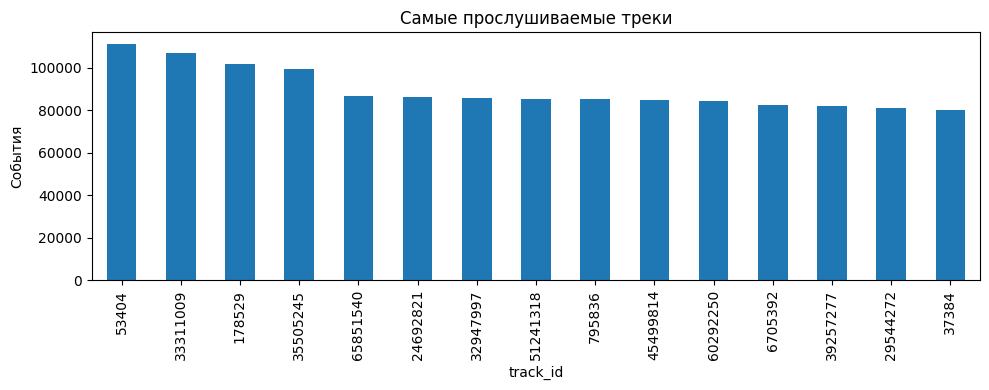

Лидер по числу событий — **Smells Like Teen Spirit** (ID 53404), 111,062 прослушиваний.

In [5]:
if RUN_MODE=='full':
    # Двухшаговая агрегация может сбрасываться на диск, в отличие от большого COUNT(DISTINCT).
    full_pairs_path=OUT/'full-pairs.parquet'
    con.execute(f"COPY (SELECT user_id,track_id,count(*)::INTEGER AS plays FROM raw_events GROUP BY user_id,track_id) TO '{full_pairs_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    user_counts = query(f"SELECT user_id,sum(plays) AS events,count(*) AS tracks FROM read_parquet('{full_pairs_path}') GROUP BY user_id")
    display(user_counts[['events','tracks']].describe(percentiles=[.5,.9,.95,.99]))
    fig,ax=plt.subplots(figsize=(9,4))
    ax.hist(user_counts.tracks,bins=80); ax.set_yscale('log')
    ax.set(xlabel='Количество разных прослушанных треков',ylabel='Пользователи (логарифмическая шкала)',title='Распределение активности пользователей'); plt.show()
    display(Markdown(f'Медиана — **{user_counts.tracks.median():.0f}** разных треков; 90% пользователей прослушали не больше **{user_counts.tracks.quantile(.9):.0f}**. Разброс активности учитываем отдельным признаком ранжирования.'))
    del user_counts; gc.collect()
    con.execute(f"CREATE TEMP TABLE item_pop AS SELECT track_id,sum(plays) AS events,count(*) AS listeners FROM read_parquet('{full_pairs_path}') GROUP BY track_id")
    popular = query(f"SELECT p.*,i.title,i.artist_names,i.album_names FROM item_pop p JOIN read_parquet('{items_path}') i USING(track_id) ORDER BY events DESC,track_id LIMIT 15")
    display(popular)
    popular.plot.bar(x='track_id',y='events',figsize=(10,4),legend=False,title='Самые прослушиваемые треки'); plt.ylabel('События'); plt.tight_layout(); plt.show()
    display(Markdown(f'Лидер по числу событий — **{popular.title.iloc[0]}** (ID {int(popular.track_id.iloc[0])}), {int(popular.events.iloc[0]):,} прослушиваний.'))
else:
    print('EDA пропущен: исходные данные не изменились.')


,genre_id,genre,full_events,fractional_events
0,11,pop,55578312.0,3.873820e+07
1,75,rap,37799821.0,1.893271e+07
2,102,allrock,31092013.0,1.508703e+07
3,20,ruspop,26626241.0,1.327947e+07
4,3,rusrap,25303695.0,1.263286e+07
5,68,electronics,20120981.0,1.547363e+07
6,16,dance,16291557.0,1.529629e+07
7,2,rusrock,13166147.0,6.560435e+06
8,14,rock,12772644.0,5.688265e+06
9,47,metal,12437375.0,6.241614e+06


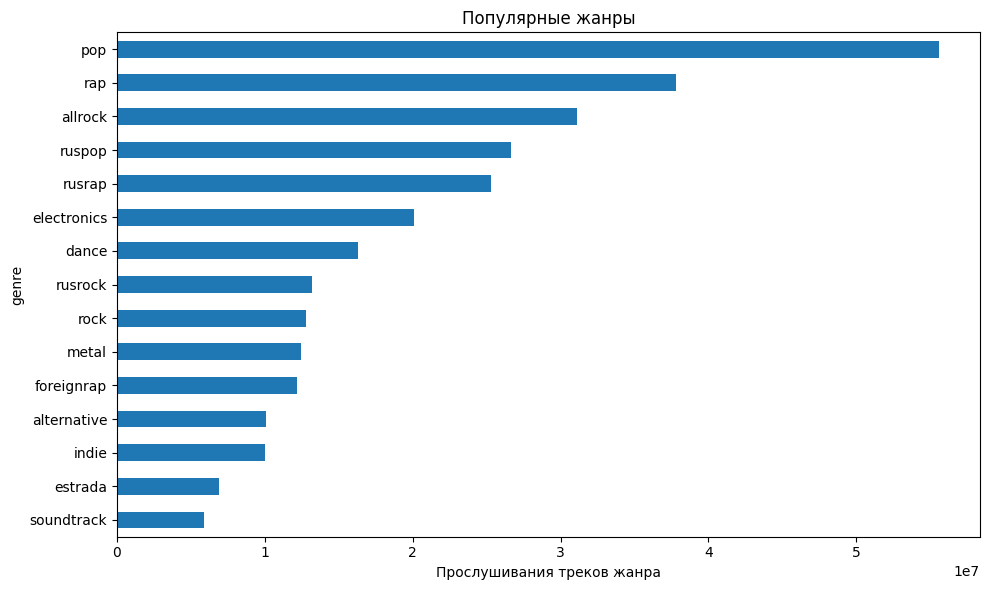

Самый популярный жанр — **pop**. Сумма полных счётчиков может быть больше числа событий: у трека бывает несколько жанров. Дробный счётчик распределяет одно событие между жанрами.

,tracks
0,0


,track_id,albums,artists,genres,title,artist_names,album_names,genre_names


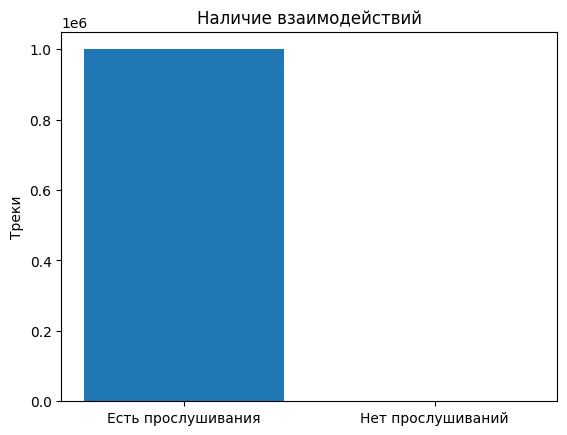

Без единого прослушивания — **0** треков. Их сохраняем в каталоге, но обучить их факторы по взаимодействиям нельзя.

In [6]:
if RUN_MODE=='full':
    # Каждый жанр получает событие целиком. Дополнительно считаем дробный вес 1 / число жанров.
    genres = query("SELECT v.id AS genre_id,coalesce(c.name,'Неизвестно') AS genre,sum(p.events) AS full_events,sum(p.events*1.0/len(list_distinct(t.genres))) AS fractional_events FROM tracks t JOIN item_pop p USING(track_id), unnest(list_distinct(t.genres)) v(id) LEFT JOIN catalog c ON c.id=v.id AND c.type='genre' GROUP BY v.id,c.name ORDER BY full_events DESC")
    display(genres.head(15))
    genres.head(15).iloc[::-1].plot.barh(x='genre',y='full_events',figsize=(10,6),legend=False,title='Популярные жанры'); plt.xlabel('Прослушивания треков жанра'); plt.tight_layout(); plt.show()
    display(Markdown(f'Самый популярный жанр — **{genres.genre.iloc[0]}**. Сумма полных счётчиков может быть больше числа событий: у трека бывает несколько жанров. Дробный счётчик распределяет одно событие между жанрами.'))
    unheard = query('SELECT count(*) AS tracks FROM tracks t ANTI JOIN item_pop p USING(track_id)')
    display(unheard)
    display(query(f"SELECT i.* FROM read_parquet('{items_path}') i ANTI JOIN item_pop p USING(track_id) ORDER BY track_id LIMIT 10"))
    heard = 1000000-int(unheard.tracks.iloc[0])
    plt.bar(['Есть прослушивания','Нет прослушиваний'],[heard,int(unheard.tracks.iloc[0])]); plt.ylabel('Треки'); plt.title('Наличие взаимодействий'); plt.show()
    display(Markdown(f'Без единого прослушивания — **{int(unheard.tracks.iloc[0]):,}** треков. Их сохраняем в каталоге, но обучить их факторы по взаимодействиям нельзя.'))
else:
    print('Повторный EDA пропущен.')


## Подготовленные файлы
После обработки я разделил данные на items.parquet с информацией о треках и events.parquet с прослушиваниями. Оба файла сохранены в персональном S3-бакете по пути `recsys/data/`.

После сохранения проверил, что файлы читаются и их содержимое совпадает с локальными данными. Это позволило использовать подготовленные таблицы в следующих расчётах без повторной обработки исходных справочников.


In [7]:
if RUN_MODE=='full':
    upload_checked(items_path,'recsys/data/items.parquet')
    upload_checked(events_path,'recsys/data/events.parquet')
    con.execute('DROP TABLE item_pop')
    del popular, genres
    gc.collect()
else:
    print('Подготовленные данные в S3 не перезаписываются.')


s3://hda-s3-20261107-6104ff762354/recsys/data/items.parquet: 1,000,000 строк; повторное чтение и SHA-256 — OK


s3://hda-s3-20261107-6104ff762354/recsys/data/events.parquet: 222,629,898 строк; повторное чтение и SHA-256 — OK


11432

# Этап 3. Как сравнивал рекомендации
Основную историю я ограничил событиями строго до 16 декабря 2022 года, а более поздние прослушивания оставил для теста. Для CatBoost понадобилось ещё одно разделение: признаки строятся по истории до 9 декабря, а метки — по прослушиваниям с 9 по 15 декабря.

Так я отделил обучение ранжирования от основного теста. При обновлении CatBoost я использовал уже подготовленные данные и проверенные модели ALS. Повторное обучение ALS для этого не понадобилось. Большие матрицы обрабатываются по очереди, чтобы уложиться в память ВМ.


In [8]:
con.execute(f"CREATE VIEW events AS SELECT * FROM read_parquet('{events_path}')")
display(query(f"SELECT CASE WHEN started_at<DATE '{INNER_END}' THEN 'до 9 декабря' WHEN started_at<DATE '{TRAIN_END}' THEN '9–15 декабря' ELSE 'основной тест' END AS period,count(*) AS events,count(DISTINCT user_id) AS users FROM events GROUP BY 1"))
users = query('SELECT DISTINCT user_id FROM events ORDER BY user_id').user_id.to_numpy()
items = query(f"SELECT track_id FROM read_parquet('{items_path}') ORDER BY track_id").track_id.to_numpy()
con.register('user_map',pd.DataFrame({'user_id':users,'u':np.arange(len(users),dtype=np.int32)}))
con.register('item_map',pd.DataFrame({'track_id':items,'i':np.arange(len(items),dtype=np.int32)}))
MAP_HASHES = dict(users=array_hash(users), items=array_hash(items))
if RUN_MODE=='resume' and MAP_HASHES!=LEGACY_EVIDENCE['maps']: raise RuntimeError('Отображения ID не совпадают с проверенными')
print('Размер матрицы:',len(users),'×',len(items),'; плотная матрица не создаётся')

def data_signature(boundary):
    return dict(source=SOURCE_HASHES, boundary=boundary, maps=MAP_HASHES,
                users=len(users), items=len(items), aggregation='count_events_by_user_item_v1')


def named_cache(name, suffix, signature):
    return CACHE/f'{name}-{fingerprint(signature)[:20]}{suffix}'


def model_signature(boundary):
    return dict(data=data_signature(boundary), parameters=ALS_PARAMS, confidence=WEIGHT_RECIPE,
                libraries={k:LIBRARY_VERSIONS[k] for k in ('numpy','scipy','implicit')}, version=1)


def als_cache_path(name, boundary):
    signature=model_signature(boundary)
    if RUN_MODE=='resume': return reuse_legacy(name+'_als',signature)
    return named_cache(name+'-als','.npz',signature)


def build_matrix(boundary, name):
    signature=data_signature(boundary)
    path=(reuse_legacy(name+'_pairs',signature) if RUN_MODE=='resume' else named_cache(name+'-pairs','.parquet',signature))
    if RUN_MODE!='resume' and not cache_valid(path,signature):
        prepare_new_cache(path)
        con.execute(f"COPY (SELECT m.u,n.i,count(*)::INTEGER AS plays FROM events e JOIN user_map m USING(user_id) JOIN item_map n USING(track_id) WHERE e.started_at<DATE '{boundary}' GROUP BY m.u,n.i ORDER BY m.u,n.i) TO '{path}' (FORMAT PARQUET,COMPRESSION ZSTD)")
        record_cache(path,signature)
    pf=pq.ParquetFile(path); nnz=pf.metadata.num_rows
    indices=np.empty(nnz,dtype=np.int32); data=np.empty(nnz,dtype=np.float32)
    counts=np.zeros(len(users),dtype=np.int64); item_counts=np.zeros(len(items),dtype=np.int64)
    offset=0; previous_u=-1
    for batch in pf.iter_batches(batch_size=500000):
        u=batch.column('u').to_numpy(); i=batch.column('i').to_numpy(); p=batch.column('plays').to_numpy()
        assert u[0]>=previous_u and np.all(np.diff(u)>=0), 'Нарушен порядок пользователей в CSR'
        previous_u=int(u[-1])
        end=offset+len(u); indices[offset:end]=i; data[offset:end]=1+WEIGHT_RECIPE['scale']*np.log1p(p)
        np.add.at(counts,u,1); np.add.at(item_counts,i,p); offset=end
    indptr=np.r_[0,np.cumsum(counts)].astype(np.int32)
    matrix=csr_matrix((data,indices,indptr),shape=(len(users),len(items)),copy=False)
    print(name, f'{nnz:,} ненулевых пар',f'{(data.nbytes+indices.nbytes+indptr.nbytes)/1e9:.2f} ГБ')
    return matrix,item_counts

def fit_model(matrix, name, boundary):
    path=als_cache_path(name,boundary); signature=model_signature(boundary)
    if RUN_MODE=='resume' or cache_valid(path,signature):
        from implicit.cpu.als import AlternatingLeastSquares as CPUALS
        model=CPUALS.load(str(path))
        assert model.user_factors.shape==(len(users),ALS_PARAMS['factors']) and model.item_factors.shape==(len(items),ALS_PARAMS['factors'])
        print(name, 'ALS загружена из проверенного сохранённого состояния')
        return model
    prepare_new_cache(path, training='als')
    model=AlternatingLeastSquares(**ALS_PARAMS)
    model.fit(matrix,show_progress=False)
    model.save(str(path)); record_cache(path,signature)
    return model


,period,events,users
0,9–15 декабря,7896335,744050
1,до 9 декабря,200834917,1321308
2,основной тест,13898646,783525


Размер матрицы: 1373221 × 1000000 ; плотная матрица не создаётся


## Популярные треки и ALS
Самая простая отправная точка — рекомендовать треки с наибольшим числом обучающих прослушиваний. Такой список не учитывает личные вкусы, но подходит для пользователей без истории. Уже прослушанные треки я исключаю из всех выдач.

Для персональных рекомендаций использовал ALS с 32 факторами и 12 итерациями. Вес пары равен `1 + 20·log(1 + число событий)`: повторные прослушивания усиливают сигнал, но логарифм сдерживает их влияние.

Перебирать миллион треков для каждого пользователя дорого, поэтому кандидатов ищет Faiss HNSW. Для найденных пар оценки ALS пересчитываются точно. Сам поиск остаётся приближённым и может пропустить подходящий трек. Для CatBoost я объединяю 50 ALS-кандидатов и 50 популярных треков; пользователей обрабатываю пакетами по 256.


In [9]:
def factor_index(model, item_counts, cosine=False, legacy_role=None):
    active=np.flatnonzero((item_counts>0)&(np.linalg.norm(model.item_factors,axis=1)>0)).astype(np.int32)
    signature=dict(factors_sha256=array_hash(model.item_factors), active_sha256=array_hash(active), cosine=cosine, hnsw=HNSW_PARAMS, faiss=LIBRARY_VERSIONS['faiss-cpu'])
    if RUN_MODE=='resume':
        if legacy_role is None: raise RuntimeError('Не указан проверенный индекс')
        info=LEGACY_EVIDENCE['artifacts'][legacy_role]
        if info['factors_sha256']!=signature['factors_sha256'] or info['active_sha256']!=signature['active_sha256'] or info['cosine']!=cosine:
            raise RuntimeError('Индекс не соответствует факторам или порядку ID')
        path=reuse_legacy(legacy_role,signature)
        index=faiss.read_index(str(path))
        assert index.ntotal==len(active) and index.d==model.item_factors.shape[1]
        assert index.metric_type==faiss.METRIC_INNER_PRODUCT
        assert index.hnsw.nb_neighbors(0)==2*HNSW_PARAMS['M']
        assert index.hnsw.efConstruction==HNSW_PARAMS['efConstruction'] and index.hnsw.efSearch==HNSW_PARAMS['efSearch']
        return index,active,path
    suffix=hashlib.sha256(json.dumps(signature,sort_keys=True).encode()).hexdigest()[:16]
    path=CACHE/('index-'+suffix+'.faiss')
    if cache_valid(path,signature):
        index=faiss.read_index(str(path)); print('Индекс загружен из проверенного состояния')
        return index,active,path
    prepare_new_cache(path)
    vec=np.ascontiguousarray(model.item_factors[active],dtype=np.float32)
    if cosine: faiss.normalize_L2(vec)
    index=faiss.IndexHNSWFlat(vec.shape[1],HNSW_PARAMS['M'],faiss.METRIC_INNER_PRODUCT)
    index.hnsw.efConstruction=HNSW_PARAMS['efConstruction']; index.hnsw.efSearch=HNSW_PARAMS['efSearch']
    # Один поток при построении делает граф воспроизводимым.
    faiss.omp_set_num_threads(HNSW_PARAMS['build_threads']); index.add(vec); faiss.omp_set_num_threads(HNSW_PARAMS['search_threads'])
    faiss.write_index(index,str(path)); record_cache(path,signature)
    return index,active,path

pop_order_cache={}

def candidates(batch, model, matrix, pop, index, active):
    rows=[]
    cache_key=id(pop)
    if cache_key not in pop_order_cache:
        order=np.lexsort((items,-pop)); pop_order_cache[cache_key]=(pop,order[pop[order]>0])
    order=pop_order_cache[cache_key][1]
    vectors=np.ascontiguousarray(model.user_factors[batch],dtype=np.float32)
    # Запас на исключение истории; при нехватке добираем популярными.
    _,found=index.search(vectors, min(CANDIDATE_PARAMS['search_count'],len(active)))
    for pos,u in enumerate(batch):
        seen=set(matrix.indices[matrix.indptr[u]:matrix.indptr[u+1]])
        p=[]
        for i in order:
            if int(i) not in seen: p.append(int(i))
            if len(p)==CANDIDATES: break
        a=[]
        if matrix.indptr[u+1]>matrix.indptr[u]:
            for f in found[pos]:
                if f>=0 and int(active[f]) not in seen: a.append(int(active[f]))
                if len(a)==CANDIDATES: break
        if len(a)<CANDIDATES: a+= [i for i in p if i not in a][:CANDIDATES-len(a)]
        ps,aset=set(p),set(a)
        ids=np.array(sorted(ps|aset),dtype=np.int32)
        scores=model.item_factors[ids]@model.user_factors[u]
        for i,score in zip(ids,scores):
            rows.append((int(u),int(i),float(score),float(np.log1p(pop[i])),float(np.log1p(len(seen))),int(i in aset),int(i in ps)))
    return pd.DataFrame(rows,columns=['u','i','als_score','log_popularity','log_activity','from_als','from_popular'])

FEATURES=['als_score','log_popularity','log_activity','from_als','from_popular']
inner_matrix, inner_pop = build_matrix(INNER_END,'inner')
inner_model=fit_model(inner_matrix,'inner',INNER_END)
inner_index,inner_active,inner_index_path=factor_index(inner_model,inner_pop,legacy_role='inner_index')
print('Внутренняя ALS обучена только по событиям до 9 декабря')


inner 200,834,917 ненулевых пар 1.61 ГБ


inner ALS загружена из проверенного сохранённого состояния


Внутренняя ALS обучена только по событиям до 9 декабря


## Чему учится CatBoost
Я выбрал пять признаков: оценку ALS, логарифм популярности трека, логарифм активности пользователя и два признака попадания в списки кандидатов. Метка равна 1, если пользователь прослушал кандидата с 9 по 15 декабря. Положительные треки специально в список не добавлял: модель работает с теми кандидатами, которые удалось найти.

Перед случайным выбором отсортировал пользователей и зафиксировал seed 42. Из 20 000 пользователей получилось 1 845 724 кандидата и 8 447 положительных меток. Для обучения оставил 4 940 групп, где есть и положительные, и отрицательные примеры. Остальные пользователи не исключаются из основной оценки.

Обучение и проверку разделил по пользователям: 3 952 пользователя, 362 729 строк и 6 799 положительных меток в обучении; 988 пользователей, 90 762 строки и 1 648 положительных меток в проверке. Группы не пересекаются.

CatBoost обучалась с YetiRank, глубиной 6, learning rate 0.08 и максимумом 200 итераций. После выбора лучшего состояния осталось 195 деревьев, проверочная NDCG@10 составила 0.182710. Основной тест с 16 декабря в обучении не участвовал.


In [10]:
eligible=query(f"SELECT DISTINCT m.u FROM events e JOIN user_map m USING(user_id) WHERE started_at>=DATE '{INNER_END}' AND started_at<DATE '{TRAIN_END}' ORDER BY m.u").u.to_numpy(dtype=np.int32)
eligible=eligible[np.diff(inner_matrix.indptr)[eligible]>0]
eligible=np.sort(eligible)  # Сортировка до выбора пользователей.
rng=np.random.default_rng(SELECTION_PARAMS['seed'])
chosen=np.sort(rng.choice(eligible,size=min(SELECTION_PARAMS['max_users'],len(eligible)),replace=False))
con.register('selected_rank_users',pd.DataFrame({'u':chosen}))
labels=query(f"SELECT DISTINCT m.u,n.i FROM events e JOIN user_map m USING(user_id) JOIN item_map n USING(track_id) JOIN selected_rank_users s ON m.u=s.u WHERE started_at>=DATE '{INNER_END}' AND started_at<DATE '{TRAIN_END}'")
frames=[]
for start in range(0,len(chosen),CANDIDATE_PARAMS['batch_size']):
    frames.append(candidates(chosen[start:start+CANDIDATE_PARAMS['batch_size']],inner_model,inner_matrix,inner_pop,inner_index,inner_active))
rank_data=pd.concat(frames,ignore_index=True); del frames
rank_data=rank_data.merge(labels.assign(target=np.int8(1)),on=['u','i'],how='left')
rank_data['target']=rank_data.target.fillna(0).astype(np.int8)
assert not rank_data.duplicated(['u','i']).any()
groups=rank_data.groupby('u').target.agg(['sum','count'])
display(groups.describe())
print('Всего кандидатов:',len(rank_data),'| положительных:',int(rank_data.target.sum()))
print('Групп без положительных:',int((groups['sum']==0).sum()),'из',len(groups))
informative=np.sort(groups.index[(groups['sum']>0)&(groups['sum']<groups['count'])].to_numpy())
assert len(informative)>=20, 'Недостаточно информативных групп для ранжирования'
val_users=set(rng.choice(informative,size=max(1,int(len(informative)*SELECTION_PARAMS['validation_fraction'])),replace=False).tolist())
rank_data=rank_data[rank_data.u.isin(informative)].sort_values(['u','i'])
train_rank=rank_data[~rank_data.u.isin(val_users)]
valid_rank=rank_data[rank_data.u.isin(val_users)]
assert set(train_rank.u).isdisjoint(set(valid_rank.u))
rank_signature=dict(
    source=SOURCE_HASHES, maps=MAP_HASHES, history_end=INNER_END, label_end=TRAIN_END,
    als_signature=model_signature(INNER_END), als_sha256=file_hash(als_cache_path('inner',INNER_END)),
    index_sha256=file_hash(inner_index_path), hnsw=HNSW_PARAMS, candidates=CANDIDATE_PARAMS,
    selection=SELECTION_PARAMS, selected_users_sha256=array_hash(chosen),
    train_sha256=frame_hash(train_rank,['u','i']+FEATURES+['target']),
    validation_sha256=frame_hash(valid_rank,['u','i']+FEATURES+['target']),
    features=FEATURES, feature_recipe=FEATURE_RECIPE, parameters=RANKER_PARAMS,
    early_stopping_rounds=EARLY_STOPPING_ROUNDS, libraries=LIBRARY_VERSIONS, version=1)
rank_path=named_cache('ranker','.cbm',rank_signature)
ranker=CatBoostRanker(**RANKER_PARAMS)
if cache_valid(rank_path,rank_signature):
    saved_info=json.loads(cache_metadata(rank_path).read_text(encoding='utf-8'))
    required_training_fields={'parameters','train_rows','train_users','validation_rows','validation_users','history_end_exclusive','labels_from_inclusive','labels_to_exclusive','seed','train_data_sha256','validation_data_sha256','validation_metric','validation_score','actual_iterations'}
    if not isinstance(saved_info.get('training'),dict) or not required_training_fields.issubset(saved_info['training']):
        raise RuntimeError('В кэше нет сведений о первоначальном обучении CatBoost. Загрузка остановлена; статистика текущих кандидатов не заменяет эти сведения.')
    ranker.load_model(str(rank_path)); assert ranker.feature_names_==FEATURES
    training_info=saved_info['training']
    assert int(ranker.tree_count_)==training_info['actual_iterations'], 'Число деревьев не совпадает со сводкой обучения'
    print('Модель загружена. Ниже — сохранённые сведения её первоначального обучения.')
else:
    prepare_new_cache(rank_path, training='catboost')
    ranker.fit(Pool(train_rank[FEATURES],label=train_rank.target,group_id=train_rank.u),
               eval_set=Pool(valid_rank[FEATURES],label=valid_rank.target,group_id=valid_rank.u),
               early_stopping_rounds=EARLY_STOPPING_ROUNDS)
    validation_score=float(eval_metric(valid_rank.target.to_numpy(),ranker.predict(valid_rank[FEATURES]),
                                      RANKER_PARAMS['eval_metric'],group_id=valid_rank.u.to_numpy(),
                                      thread_count=RANKER_PARAMS['thread_count'])[0])
    training_info=dict(
        trained_at_utc=datetime.now(timezone.utc).isoformat(), parameters=RANKER_PARAMS,
        early_stopping_rounds=EARLY_STOPPING_ROUNDS, seed=SEED,
        history_end_exclusive=INNER_END, labels_from_inclusive=INNER_END, labels_to_exclusive=TRAIN_END,
        source=SOURCE_HASHES, signature_sha256=fingerprint(rank_signature),
        train_data_sha256=rank_signature['train_sha256'], validation_data_sha256=rank_signature['validation_sha256'],
        selected_users=len(chosen), informative_groups=len(informative), candidate_rows=int(groups['count'].sum()), candidate_positives=int(groups['sum'].sum()), train_rows=len(train_rank), train_users=int(train_rank.u.nunique()),
        validation_rows=len(valid_rank), validation_users=int(valid_rank.u.nunique()),
        train_positives=int(train_rank.target.sum()), validation_positives=int(valid_rank.target.sum()),
        validation_metric=RANKER_PARAMS['eval_metric'], validation_score=validation_score,
        actual_iterations=int(ranker.tree_count_), best_iteration_zero_based=int(ranker.get_best_iteration()))
    ranker.save_model(str(rank_path)); record_cache(rank_path,rank_signature,training_info)
display(pd.DataFrame({'поле':list(training_info),'значение':[str(v) for v in training_info.values()]}).style.set_properties(**{'white-space':'pre-wrap'}))
display(pd.DataFrame({'признак':FEATURES,'важность':ranker.get_feature_importance(type='PredictionValuesChange')}).sort_values('важность',ascending=False))
print('Деревьев:',training_info['actual_iterations'],'|',training_info['validation_metric'],training_info['validation_score'])
del inner_matrix,inner_model,inner_index,inner_pop,inner_active,rank_data,train_rank,valid_rank,labels
gc.collect()


,sum,count
count,20000.000000,20000.000000
mean,0.422350,92.286200
std,1.018441,6.906814
min,0.000000,59.000000
25%,0.000000,88.000000
50%,0.000000,94.000000
75%,0.000000,98.000000
max,17.000000,100.000000


Всего кандидатов: 1845724 | положительных: 8447
Групп без положительных: 15060 из 20000


,поле,значение
0,trained_at_utc,2026-11-21T10:42:55.364469+00:00
1,parameters,"{'iterations': 200, 'depth': 6, 'learning_rate': 0.08, 'loss_function': 'YetiRank', 'eval_metric': 'NDCG:top=10', 'random_seed': 42, 'thread_count': 6, 'allow_writing_files': False, 'verbose': False}"
2,early_stopping_rounds,25
3,seed,42
4,history_end_exclusive,2022-12-09
5,labels_from_inclusive,2022-12-09
6,labels_to_exclusive,2022-12-16
7,source,"{'tracks': '6e6050eeea39cb23344cf6341b513060c873acfa4fa6ea9e16bdfcca121a611e', 'interactions': '5edc7f5f0624a7651691894ea44375fcd6ea2689bda8f9aed1edaf28f8a68796'}"
8,signature_sha256,02cbbfb2da23002cc2275fa1fb994fd977581d1f88d369d94b7d792fcf57ab7a
9,train_data_sha256,92c7f2e371c0423485be55350b5eb85ec952b4a7cb7d0b6696cc0e05c5d823b4


,признак,важность
1,log_popularity,53.080331
0,als_score,26.710167
2,log_activity,11.309346
3,from_als,8.900156
4,from_popular,0.000000


Деревьев: 195 | NDCG:top=10 0.18270980587257493


50

## Итоговые списки
После обучения я применил CatBoost к кандидатам, найденным по основной истории до 16 декабря. Модель переупорядочила объединение персональных и популярных треков, а в итоговую выдачу попали первые десять.

Расчёт шёл частями: всего получилось 54 блока и 13 732 210 строк для 1 373 221 пользователя. Готовые части сохранялись отдельно, чтобы при остановке не начинать всё сначала. Проверки показали, что у каждого пользователя ровно десять разных рекомендаций с рангами 1–10, без уже прослушанных треков, неизвестных ID и недопустимых оценок.

Новая выдача опубликована в S3. Сообщения ниже об отсутствии записи относятся к самому расчёту: публикация прошла отдельно после проверки результатов.


In [12]:
matrix,pop = build_matrix(TRAIN_END,'train')
model=fit_model(matrix,'train',TRAIN_END)
index,active,final_index_path=factor_index(model,pop,legacy_role='train_index')
base_data=data_signature(TRAIN_END)
popular_signature=dict(data=base_data,k=K,exclude_seen=True,ties='track_id_ascending',version=1)
als_signature=dict(data=base_data,k=K,model_signature=model_signature(TRAIN_END),
                   model_sha256=file_hash(als_cache_path('train',TRAIN_END)),candidates=CANDIDATE_PARAMS,
                   hnsw=HNSW_PARAMS,index_sha256=file_hash(final_index_path),version=1)
final_signature=dict(base=als_signature,popular=popular_signature,ranker=file_hash(rank_path),
                     ranker_signature=fingerprint(rank_signature),features=FEATURES,
                     feature_recipe=FEATURE_RECIPE,libraries=LIBRARY_VERSIONS,version=4)
method_signatures={'top_popular':popular_signature,'personal_als':als_signature,'recommendations':final_signature}
schema=pa.schema([('user_id',pa.int64()),('track_id',pa.int64()),('score',pa.float32()),('rank',pa.int16())])
paths={}; native_methods=[]
for name,signature in method_signatures.items():
    if RUN_MODE=='resume' and name!='recommendations':
        paths[name]=reuse_legacy(name,signature)
    else:
        folder=OUT/'recommendations'/name/fingerprint(signature)[:20]
        folder.mkdir(parents=True,exist_ok=True)
        paths[name]=folder/(name+'.parquet')
        if not result_ready(paths[name],signature):
            if paths[name].exists(): raise RuntimeError('Существующий итоговый файл не прошёл проверку; он сохранён: '+str(paths[name]))
            native_methods.append(name)
folders={name:CACHE/'recommendation-parts'/name/fingerprint(method_signatures[name])[:20] for name in native_methods}
for folder in folders.values(): folder.mkdir(parents=True,exist_ok=True)
completed={name:[] for name in native_methods}
for chunk_start in range(0,len(users),25600):
    if shutil.disk_usage(WORK).free<8*1024**3: raise RuntimeError('Недостаточно свободного диска; завершённые блоки сохранены')
    chunk_end=min(chunk_start+25600,len(users)); writers={}; pending={}
    for name in native_methods:
        sig=block_signature(method_signatures[name],chunk_start,chunk_end)
        ready=ready_block(folders[name],sig,chunk_start,chunk_end)
        if ready is not None:
            completed[name].append(ready)
            continue
        temporary,complete=pending_block(folders[name],sig,chunk_start)
        pending[name]=(temporary,complete,sig)
        block_schema=schema.with_metadata({b'recsys_signature':fingerprint(sig).encode()})
        writers[name]=pq.ParquetWriter(temporary,block_schema,compression='zstd')
    try:
        if writers:
            for start in range(chunk_start,chunk_end,CANDIDATE_PARAMS['batch_size']):
                batch=np.arange(start,min(start+CANDIDATE_PARAMS['batch_size'],chunk_end),dtype=np.int32)
                frame=candidates(batch,model,matrix,pop,index,active)
                cold=frame.log_activity==0
                frame['personal_score']=frame.als_score.where(~cold,frame.log_popularity)
                if 'recommendations' in writers:
                    frame['rank_score']=ranker.predict(frame[FEATURES])
                    frame.loc[cold,'rank_score']=frame.loc[cold,'log_popularity']
                for name,writer in writers.items():
                    score={'top_popular':'log_popularity','personal_als':'personal_score','recommendations':'rank_score'}[name]
                    subset=frame if name=='recommendations' else frame[frame['from_popular' if name=='top_popular' else 'from_als']==1]
                    top=subset.sort_values(['u',score,'i'],ascending=[True,False,True]).groupby('u',sort=False).head(K).copy()
                    top['rank']=top.groupby('u',sort=False).cumcount()+1
                    result=pd.DataFrame({'user_id':users[top.u.to_numpy()],'track_id':items[top.i.to_numpy()],
                                         'score':top[score].to_numpy(dtype=np.float32),'rank':top['rank'].to_numpy(dtype=np.int16)})
                    assert len(result)==len(batch)*K
                    table=pa.Table.from_pandas(result,schema=schema,preserve_index=False)
                    table=table.replace_schema_metadata({b'recsys_signature':fingerprint(pending[name][2]).encode()})
                    writer.write_table(table)
    finally:
        for writer in writers.values(): writer.close()
    for name,(temporary,complete,sig) in pending.items():
        # Сбой до этой точки оставляет .partial; он не считается готовым и не удаляется.
        if not block_structure_ok(temporary,sig,chunk_start,chunk_end): raise RuntimeError('Неполный блок: '+str(temporary))
        temporary.replace(complete)  # Имя UUID новое, прежние файлы не перезаписываются.
        record_cache(complete,sig)
        completed[name].append(complete)
    if native_methods: print(f'Готовые блоки: {chunk_end:,}/{len(users):,}',flush=True)
for name in native_methods:
    path=paths[name]; signature=method_signatures[name]
    if path.exists(): raise RuntimeError('Существующий итоговый файл не прошёл проверку; он сохранён: '+str(path))
    temporary=path.with_name(path.name+'.'+uuid.uuid4().hex+'.partial')
    result_metadata={b'recsys_signature':fingerprint(signature).encode()}
    with pq.ParquetWriter(temporary,schema.with_metadata(result_metadata),compression='zstd') as writer:
        for part in completed[name]:
            for batch in pq.ParquetFile(part).iter_batches(batch_size=250000):
                writer.write_batch(batch.replace_schema_metadata(result_metadata))
    assert pq.ParquetFile(temporary).metadata.num_rows==len(users)*K
    temporary.replace(path); record_cache(path,signature)
for name,path in paths.items():
    con.execute(f"CREATE VIEW rec_{name} AS SELECT * FROM read_parquet('{path}')")
    validate_recommendations(f'rec_{name}')
    upload_checked(path,'recsys/recommendations/'+path.name)


train 208,731,252 ненулевых пар 1.68 ГБ


train ALS загружена из проверенного сохранённого состояния


Готовые блоки: 25,600/1,373,221


Готовые блоки: 51,200/1,373,221


Готовые блоки: 76,800/1,373,221


Готовые блоки: 102,400/1,373,221


... (49 outputs left out)

Готовые блоки: 1,373,221/1,373,221


S3 без изменений: recsys/recommendations/top_popular.parquet


S3 без изменений: recsys/recommendations/personal_als.parquet


S3 без изменений: recsys/recommendations/recommendations.parquet


## Похожие треки
Кроме пользовательских списков я подготовил похожие треки. Близость здесь определяется косинусным сходством нормированных факторов ALS. Faiss находит соседей, после чего для найденных пар считаются точные оценки. Сам трек в собственные соседи не попадает.

В файле сохранены 9 996 950 строк для 999 695 треков с обучающей историей. Для 305 треков без событий до границы обучения такие соседи не рассчитывались. При обновлении CatBoost я использовал этот файл повторно: изменение ранжирования пользователей не меняет сходство факторов ALS.

Часть подробностей первого обучения ALS, включая сведения о взвешенной матрице, не сохранилась. Я проверил данные, параметры моделей и соответствие индексов. Ошибок не нашёл, но полностью восстановить условия первоначального обучения ALS уже не получится.


In [13]:
# Убеждаемся, что кэш популярности соответствует всему основному обучению.
expected_order=np.lexsort((items,-pop)); expected_order=expected_order[pop[expected_order]>0]
if id(pop) not in pop_order_cache: pop_order_cache[id(pop)]=(pop,expected_order)
cached_order=pop_order_cache[id(pop)]
if isinstance(cached_order,tuple): cached_order=cached_order[1]
assert np.array_equal(cached_order,expected_order), 'Кэш популярности не соответствует основному обучению'
del expected_order
print('Порядок популярности основной тренировочной выборки проверен')
del index; gc.collect()
if RUN_MODE=='resume':
    similar_index_path=reuse_legacy('train_cosine_index',dict(data=data_signature(TRAIN_END),hnsw=HNSW_PARAMS,metric='cosine'))
    sim_signature=dict(data=data_signature(TRAIN_END),model_sha256=file_hash(als_cache_path('train',TRAIN_END)),
                       index_sha256=file_hash(similar_index_path),hnsw=HNSW_PARAMS,k=K,metric='cosine',version=1)
    similar_path=reuse_legacy('similar',sim_signature)
    print('i2i используется из проверенного файла; поиск соседей не повторяется.')
else:
    similar_index,similar_active,similar_index_path=factor_index(model,pop,cosine=True,legacy_role='train_cosine_index')
    sim_schema=pa.schema([('track_id',pa.int64()),('similar_track_id',pa.int64()),('score',pa.float32()),('rank',pa.int16())])
    sim_signature=dict(model_signature=model_signature(TRAIN_END),model=file_hash(als_cache_path('train',TRAIN_END)),maps=MAP_HASHES,boundary=TRAIN_END,k=K,metric='cosine',hnsw=HNSW_PARAMS,index_sha256=file_hash(similar_index_path),faiss=LIBRARY_VERSIONS['faiss-cpu'],exclude_self=True,rerank='exact_cosine',version=3)
    similar_dir=OUT/'similar'/fingerprint(sim_signature)[:20]
    similar_dir.mkdir(parents=True,exist_ok=True)
    similar_path=similar_dir/'similar.parquet'
    if not cache_valid(similar_path,sim_signature):
        prepare_new_cache(similar_path)
        with pq.ParquetWriter(similar_path,sim_schema,compression='zstd') as writer:
            for start in range(0,len(similar_active),2048):
                batch=similar_active[start:start+2048]
                vectors=np.ascontiguousarray(model.item_factors[batch],dtype=np.float32); faiss.normalize_L2(vectors)
                _,neighbors=similar_index.search(vectors,K+1)
                src=[]; dst=[]; scores=[]; ranks=[]
                for row,i in enumerate(batch):
                    js=[int(similar_active[n]) for n in neighbors[row] if n>=0 and similar_active[n]!=i][:K]
                    vals=np.ascontiguousarray(model.item_factors[js],dtype=np.float32); faiss.normalize_L2(vals)
                    exact=vals@vectors[row]
                    order=np.lexsort((items[js],-exact))
                    src.extend([int(items[i])]*len(js)); dst.extend(items[np.array(js)[order]].tolist()); scores.extend(exact[order].tolist()); ranks.extend(range(1,len(js)+1))
                writer.write_table(pa.Table.from_pydict({'track_id':src,'similar_track_id':dst,'score':scores,'rank':ranks},schema=sim_schema))
            print('Треков с обучающей историей:',len(similar_active))
        record_cache(similar_path,sim_signature)
    else:
        print('Похожие треки загружены из проверенного сохранённого файла')
validate_similar(similar_path)
upload_checked(similar_path,'recsys/recommendations/similar.parquet')
if RUN_MODE=='full': del similar_index
del model, matrix; gc.collect()


Порядок популярности основной тренировочной выборки проверен


i2i используется из проверенного файла; поиск соседей не повторяется.


S3 без изменений: recsys/recommendations/similar.parquet


0

## Сравнение качества
Я оценил три метода при K = 10 на одних 783 525 пользователях с новыми тестовыми треками. Повторные прослушивания одного тестового трека считаются одной релевантной парой. Треки из обучающей истории исключены и из выдачи, и из релевантного набора. Пользователь без оставшихся новых треков исключался бы одинаково для всех методов; в этом тесте таких пользователей нет.

- **Precision@10** — какая часть десяти рекомендаций попала в новые тестовые прослушивания, в среднем по пользователям.
- **Recall@10** — какую долю новых тестовых треков пользователя удалось найти, также в среднем по пользователям.
- **Coverage@10** — какая доля полного каталога встретилась в рекомендациях оцениваемым пользователям. Знаменатель — 1 000 000 треков.
- **Novelty@10** — насколько непопулярные треки попали в выдачу: среднее `−log₂((n_i + 1) / (N + M))`. Здесь `n_i` — обучающие события трека, `N` — все обучающие события, `M` — размер каталога. Чем выше значение, тем менее популярны рекомендации; само по себе это ещё не означает, что они полезнее.

Популярность для Novelty взята только из обучения. Среди оцениваемых пользователей 30 655 не имеют обучающей истории и получают популярные треки. Ниже я также показал число тестовых треков без обучающих событий.


Пользователей с тестом: 783525 | с новыми тестовыми треками: 783525 | исключено: 0


,Метод,Precision@10,Recall@10,Coverage@10,Novelty@10
0,Популярные,0.004893,0.003522,0.000134,11.220670
1,ALS,0.011417,0.015432,0.011107,12.611400
2,Ранжирование,0.012136,0.014426,0.016993,13.072112


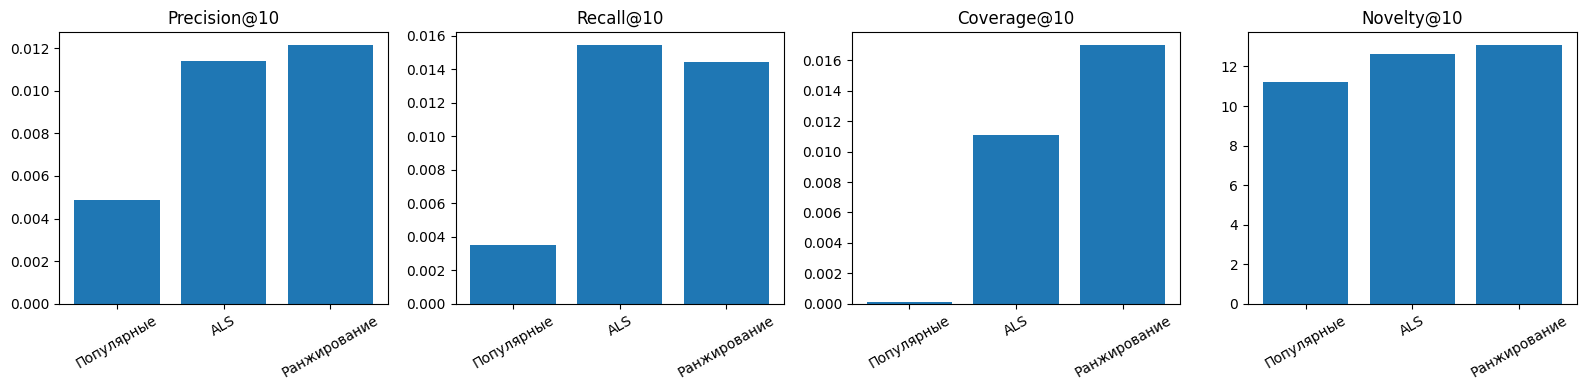

,evaluated_users,cold_users
0,783525,30655


,unique_test_tracks,cold_tracks
0,594326,305


In [14]:
con.execute(f"CREATE TEMP TABLE truth AS SELECT DISTINCT e.user_id,e.track_id FROM events e WHERE e.started_at>=DATE '{TRAIN_END}' AND NOT EXISTS (SELECT 1 FROM events h WHERE h.user_id=e.user_id AND h.track_id=e.track_id AND h.started_at<DATE '{TRAIN_END}')")
con.execute('CREATE TEMP TABLE eval_users AS SELECT user_id,count(*) AS relevant FROM truth GROUP BY user_id')
total_test=query(f"SELECT count(DISTINCT user_id) AS n FROM events WHERE started_at>=DATE '{TRAIN_END}'").n.iloc[0]
eval_n=query('SELECT count(*) AS n FROM eval_users').n.iloc[0]
print('Пользователей с тестом:',total_test,'| с новыми тестовыми треками:',eval_n,'| исключено:',total_test-eval_n)
con.register('train_pop',pd.DataFrame({'track_id':items,'plays':pop}))
total=float(pop.sum()); catalog_size=len(items)
metrics=[]
for name,title in [('top_popular','Популярные'),('personal_als','ALS'),('recommendations','Ранжирование')]:
    row=query(f"WITH hits AS (SELECT r.user_id,count(t.track_id) AS hits FROM rec_{name} r JOIN eval_users u USING(user_id) LEFT JOIN truth t ON r.user_id=t.user_id AND r.track_id=t.track_id WHERE r.rank<={K} GROUP BY r.user_id) SELECT avg(coalesce(h.hits,0)*1.0/{K}) AS precision,avg(coalesce(h.hits,0)*1.0/u.relevant) AS recall FROM eval_users u LEFT JOIN hits h USING(user_id)").iloc[0]
    extra=query(f"SELECT count(DISTINCT r.track_id)*1.0/{catalog_size} AS coverage,avg(-log2((p.plays+1.0)/{total+catalog_size})) AS novelty FROM rec_{name} r JOIN eval_users u USING(user_id) JOIN train_pop p USING(track_id) WHERE r.rank<={K}").iloc[0]
    metrics.append({'Метод':title,'Precision@10':row.precision,'Recall@10':row.recall,'Coverage@10':extra.coverage,'Novelty@10':extra.novelty})
metrics=pd.DataFrame(metrics)
display(metrics.style.format({c:'{:.6f}' for c in metrics.columns[1:]}))
fig,axes=plt.subplots(1,4,figsize=(16,4))
for ax,col in zip(axes,metrics.columns[1:]):
    ax.bar(metrics['Метод'],metrics[col]); ax.set_title(col); ax.tick_params(axis='x',rotation=30)
plt.tight_layout(); plt.show()
display(query(f"SELECT count(*) AS evaluated_users,count(*) FILTER(WHERE NOT EXISTS(SELECT 1 FROM events e WHERE e.user_id=u.user_id AND e.started_at<DATE '{TRAIN_END}')) AS cold_users FROM eval_users u"))
display(query('SELECT count(*) AS unique_test_tracks,count(*) FILTER(WHERE p.plays=0) AS cold_tracks FROM (SELECT DISTINCT track_id FROM truth) t JOIN train_pop p USING(track_id)'))


# Что получилось
Популярные рекомендации дают всем пользователям похожую отправную точку. ALS учитывает историю, а CatBoost выбирает порядок среди персональных и популярных кандидатов. По сохранённым результатам оба персональных подхода лучше популярного списка по точности и полноте. Это согласуется с тем, что личная история помогает различать интересы пользователей.

У CatBoost Precision@10 = 0.012136 против 0.011417 у ALS. Но по Recall@10 преимущество осталось у ALS: 0.015432 против 0.014426. Значит, ранжирование немного повысило долю попаданий в десяти рекомендациях, но в среднем нашло меньшую долю новых треков пользователя.

CatBoost также дала больший охват каталога — 0.016993 против 0.011107 — и новизну 13.072112 против 12.611400. Поэтому я не могу назвать один метод лучшим по всем показателям: выбор зависит от того, что важнее для рекомендации.

По сравнению с прежним вариантом CatBoost точность выросла с 0.012105, а полнота снизилась с 0.014533, охват — с 0.018216 и новизна — с 13.094682. Новая выборка обучения не улучшила всё сразу.

Ограничения остались: приближённый поиск может терять кандидатов, у ALS нет обученных факторов для треков без истории, а CatBoost использует ограниченную выборку и пять простых признаков. Кроме того, для первоначального обучения ALS не сохранилась полная информация о взвешенной матрице. В дальнейшем я бы сравнил способы поиска кандидатов и попробовал признаки музыкальных предпочтений. Эти улучшения здесь не реализованы. Попадания в будущие прослушивания ещё не доказывают, что пользователь стал бы слушать музыку иначе благодаря рекомендациям.


In [15]:
best=metrics.loc[metrics['Recall@10'].idxmax()]
display(Markdown(f"На этом тесте лучший Recall@10 у метода **{best['Метод']}**: **{best['Recall@10']:.6f}**. Числа выше получены выполнением кода, без ручной подстановки."))
saved=[]
for path,key in [(items_path,'recsys/data/items.parquet'),(events_path,'recsys/data/events.parquet')]+[(p,'recsys/recommendations/'+p.name) for p in [paths['top_popular'],paths['personal_als'],similar_path,paths['recommendations']]]:
    if PUBLISH_S3:
        head=get_s3().head_object(Bucket=BUCKET,Key=key)
        assert head['ContentLength']==path.stat().st_size
    saved.append({'Локальный файл':str(path),'Ключ S3':f's3://{BUCKET}/{key}','Публикация в этом запуске':('выполнена' if PUBLISH_S3 and (RUN_MODE=='full' or key=='recsys/recommendations/recommendations.parquet') else 'не выполнялась'),'строк':pq.ParquetFile(path).metadata.num_rows,'байт':path.stat().st_size})
display(pd.DataFrame(saved))
print('Локальные результаты проверены. S3 изменялось только при явном PUBLISH_S3=True; в resume публикуется лишь новая итоговая выдача.')


На этом тесте лучший Recall@10 у метода **ALS**: **0.015432**. Числа выше получены выполнением кода, без ручной подстановки.

,Локальный файл,Ключ S3,Публикация в этом запуске,строк,байт
0,/home/ubuntu/recsys-data/output/items.parquet,s3://hda-s3-20261107-6104ff762354/recsys/data/...,не выполнялась,1000000,41209947
1,/home/ubuntu/recsys-data/output/events.parquet,s3://hda-s3-20261107-6104ff762354/recsys/data/...,не выполнялась,222629898,959492260
2,/home/ubuntu/recsys-data/output/top_popular.pa...,s3://hda-s3-20261107-6104ff762354/recsys/recom...,не выполнялась,13732210,8757355
3,/home/ubuntu/recsys-data/output/personal_als.p...,s3://hda-s3-20261107-6104ff762354/recsys/recom...,не выполнялась,13732210,104696040
4,/home/ubuntu/recsys-data/output/similar.parquet,s3://hda-s3-20261107-6104ff762354/recsys/recom...,не выполнялась,9996950,98000115
5,/home/ubuntu/recsys-data/output-v3/recommendat...,s3://hda-s3-20261107-6104ff762354/recsys/recom...,не выполнялась,13732210,79164691


Локальные результаты проверены. S3 изменялось только при явном PUBLISH_S3=True; в resume публикуется лишь новая итоговая выдача.
